# 11. Geospatial Regression Model

## 1. Introduction

### 1.1 Objective

The objective of this notebook is to develop an interpretable geospatial regression model to predict monthly rental prices in Chicago using property characteristics and geographic coordinates.

The preliminary modeling analysis identified Histogram-based Gradient Boosting as the best-performing model, achieving the following validation metrics:

- **MAE:** $229.22
- **RMSE:** $396.24
- **$R^2$:** 0.8331

However, the preliminary models represented geographic location primarily through ZIP codes.

This notebook explores whether latitude and longitude can provide additional information about spatial variation in rental prices.

### 1.2 Modeling Approach

We will develop a spline-based additive regression model that combines:

- Structural property characteristics, such as bedrooms, bathrooms, and square footage.
- Geographic coordinates (latitude and longitude).
- Nonlinear spatial effects represented using spline transformations.

The model will be implemented using scikit-learn, combining `SplineTransformer` and regularized linear regression (`Ridge`).

This approach provides a relatively simple and interpretable approximation to a geospatial Generalized Additive Model (GAM).

### 1.3 Evaluation Strategy

To ensure comparability with the preliminary models, we will:

1. Use the same prepared Chicago rental dataset.
2. Reproduce the group-aware training, validation, and test split using `uru_id` and the same random seed.
3. Fit all preprocessing transformations exclusively on the training set.
4. Evaluate predictive performance on the validation set using MAE, RMSE, and $R^2$.
5. Compare the geospatial model with the preliminary regression benchmarks.

The test set will not be used for model development or selection.

### 1.4 Expected Outcome

The goal is to assess whether incorporating geographic coordinates through smooth nonlinear functions can provide a useful and interpretable representation of spatial rental price variation.

Predictive accuracy and interpretability will both be considered when evaluating the model.

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Data splitting
from sklearn.model_selection import GroupShuffleSplit

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

# Modeling
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

# Model evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Visualization
import matplotlib.pyplot as plt

# Reproducibility
seed = 710
np.random.seed(seed)


## 2. Data Loading and Geographic Exploration

### 2.1 Load Prepared Chicago Rental Data

We use the same prepared Chicago rental dataset as in the preliminary modeling notebook to ensure consistency across experiments.

The dataset includes property characteristics, monthly rental prices, rental unit identifiers, and geographic coordinates.

We first verify the dataset dimensions and confirm that the geographic variables required for the spatial regression model are available.

In [2]:
# Load prepared Chicago rental dataset
df = pd.read_csv(
    "../../data/processed/chicago_prepared_full.csv",
    dtype={"address_zip": "string"},
    parse_dates=["creation_time"],
    low_memory=False
)

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check geographic variables
geo_features = ["latitude", "longitude"]

print("\nGeographic variables:")
print(df[geo_features].dtypes)

# Preview geographic coordinates
display(df[geo_features].head())


Dataset shape: (545312, 49)

Geographic variables:
latitude     float64
longitude    float64
dtype: object


,latitude,longitude
0,41.994980,-87.656840
1,41.895200,-87.653970
2,41.853916,-87.624672
3,41.853916,-87.624672
4,41.925404,-87.708099


### 2.2 Geographic Data Quality

Before developing the geospatial regression model, we examine the completeness and validity of the geographic coordinates.

We assess missing values, coordinate ranges, and the number of unique coordinate pairs.

This preliminary assessment helps determine whether latitude and longitude can be used reliably as geographic predictors.

In [3]:
# Check missing geographic coordinates
print("Missing geographic coordinates:")
print(df[geo_features].isna().sum())

print("\nPercentage of missing values:")
print((df[geo_features].isna().mean() * 100).round(2))

# Summarize coordinate distributions
print("\nGeographic coordinate summary:")
display(df[geo_features].describe())

# Count unique coordinate pairs
unique_coordinates = df[geo_features].dropna().drop_duplicates()

print("\nNumber of unique coordinate pairs:", len(unique_coordinates))

# Check coordinates outside valid global ranges
invalid_coordinates = (
    df["latitude"].notna()
    & df["longitude"].notna()
    & (
        ~df["latitude"].between(-90, 90)
        | ~df["longitude"].between(-180, 180)
    )
)

print("Observations with invalid coordinate ranges:", invalid_coordinates.sum())


Missing geographic coordinates:
latitude     0
longitude    0
dtype: int64

Percentage of missing values:
latitude     0.0
longitude    0.0
dtype: float64

Geographic coordinate summary:


,latitude,longitude
count,545312.000000,545312.000000
mean,41.912069,-87.704285
std,0.178235,0.203256
min,40.107159,-89.127007
25%,41.871590,-87.709709
50%,41.919300,-87.656586
75%,41.962357,-87.634369
max,42.743649,-86.766037



Number of unique coordinate pairs: 53155
Observations with invalid coordinate ranges: 0


### 2.3 Geographic Coverage

Although all observations have valid geographic coordinates, some locations may fall outside the central Chicago area.

We examine the geographic coverage using an approximate bounding box around Chicago and its surrounding metropolitan area.

This exploratory check helps identify potentially distant observations before fitting the geospatial regression model. The bounding box is not an official administrative boundary, and observations outside it are not automatically considered invalid.

In [4]:
# Approximate bounding box for the Chicago metropolitan area
lat_min, lat_max = 41.0, 42.5
lon_min, lon_max = -88.5, -87.0

# Identify observations within the approximate geographic area
within_chicago_area = (
    df["latitude"].between(lat_min, lat_max)
    & df["longitude"].between(lon_min, lon_max)
)

# Geographic coverage summary
n_total = len(df)
n_inside = within_chicago_area.sum()
n_outside = (~within_chicago_area).sum()

print(f"Total observations: {n_total:,}")
print(f"Within approximate Chicago area: {n_inside:,}")
print(f"Outside approximate Chicago area: {n_outside:,}")
print(f"Percentage outside: {n_outside / n_total * 100:.2f}%")

# Coordinate summary for observations outside the area
if n_outside > 0:
    print("\nCoordinates outside the approximate Chicago area:")
    display(
        df.loc[
            ~within_chicago_area,
            ["latitude", "longitude"]
        ].describe()
    )


Total observations: 545,312
Within approximate Chicago area: 526,253
Outside approximate Chicago area: 19,059
Percentage outside: 3.50%

Coordinates outside the approximate Chicago area:


,latitude,longitude
count,19059.000000,19059.000000
mean,42.273131,-87.777654
std,0.452635,0.591672
min,40.107159,-89.127007
25%,41.712542,-87.880974
50%,42.581261,-87.849945
75%,42.631035,-87.783005
max,42.743649,-86.766037


## 3. Geospatial Regression Model Development

### 3.1 Feature Selection and Data Splitting

We develop a spline-based additive regression model using property characteristics, temporal variables, and geographic coordinates.

The geographic predictors, latitude and longitude, are included to capture nonlinear spatial variation in rental prices.

All observations are retained because the geographic exploration did not identify missing coordinates or values outside globally valid coordinate ranges. The exploratory Chicago-area bounding box is not used to filter the dataset.

To ensure comparability with the preliminary models, we reproduce the same group-aware training, validation, and test split using `uru_id` and a fixed random seed.

The model will be trained on the training set and evaluated on the validation set. The test set will remain reserved for final evaluation.

In [5]:
# Define predictor variables
feature_columns = [
    "bedrooms",
    "full_baths",
    "square_feet",
    "year_built",
    "address_zip",
    "uru_type",
    "listing_year",
    "listing_month",
    "latitude",
    "longitude"
]

# Define predictors, target, and grouping variable
X = df[feature_columns]
y = df["rent_amount"]
groups = df["uru_id"]

# First split: development (80%) and test (20%)
gss_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=seed
)

dev_idx, test_idx = next(
    gss_test.split(X, y, groups=groups)
)

X_dev = X.iloc[dev_idx]
X_test = X.iloc[test_idx]

y_dev = y.iloc[dev_idx]
y_test = y.iloc[test_idx]

groups_dev = groups.iloc[dev_idx]

# Second split: training (80% of development)
# and validation (20% of development)
gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=seed
)

train_idx, val_idx = next(
    gss_val.split(X_dev, y_dev, groups=groups_dev)
)

X_train = X_dev.iloc[train_idx]
X_val = X_dev.iloc[val_idx]

y_train = y_dev.iloc[train_idx]
y_val = y_dev.iloc[val_idx]

# Check split sizes
print("Dataset split summary:")
print(f"Training:   {len(X_train):,} observations")
print(f"Validation: {len(X_val):,} observations")
print(f"Test:       {len(X_test):,} observations")

# Check for overlapping rental units
train_units = set(groups.loc[X_train.index])
val_units = set(groups.loc[X_val.index])
test_units = set(groups.loc[X_test.index])

assert train_units.isdisjoint(val_units)
assert train_units.isdisjoint(test_units)
assert val_units.isdisjoint(test_units)

print("\nNo overlapping rental units across splits.")


Dataset split summary:
Training:   348,494 observations
Validation: 87,942 observations
Test:       108,876 observations

No overlapping rental units across splits.


### 3.2 Feature Preprocessing

Before constructing the regression pipeline, we examine missing values in the selected predictors.

Numerical, categorical, and geographic variables will be processed separately. Geographic coordinates will be transformed using spline basis functions to capture nonlinear spatial effects, while Ridge regression will provide regularization.

All preprocessing transformations will be fitted exclusively on the training data to prevent data leakage.

In [6]:
# Examine missing values in the training predictors
missing_summary = pd.DataFrame({
    "Missing Count": X_train.isna().sum(),
    "Missing (%)": X_train.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    "Missing (%)",
    ascending=False
)

display(missing_summary.round(2))


,Missing Count,Missing (%)
year_built,113935,32.69
square_feet,19321,5.54
full_baths,111,0.03
bedrooms,0,0.00
address_zip,0,0.00
uru_type,0,0.00
listing_year,0,0.00
listing_month,0,0.00
latitude,0,0.00
longitude,0,0.00


In [7]:
# Define feature groups
numeric_features = [
    "bedrooms",
    "full_baths",
    "square_feet"
]

year_feature = ["year_built"]

categorical_features = [
    "address_zip",
    "uru_type",
    "listing_year",
    "listing_month"
]

geographic_features = [
    "latitude",
    "longitude"
]

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Year built: imputation with missing-value indicator
year_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

# Geographic preprocessing
geographic_transformer = Pipeline([
    ("splines", SplineTransformer(
        n_knots=6,
        degree=3,
        knots="quantile",
        extrapolation="constant"
    )),
    ("scaler", StandardScaler())
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("year", year_transformer, year_feature),
    ("categorical", categorical_transformer, categorical_features),
    ("geographic", geographic_transformer, geographic_features)
])

print("Preprocessing pipelines defined successfully.")


Preprocessing pipelines defined successfully.


### 3.3 Model Training

We fit a geospatial regression model using Ridge regression with spline-transformed latitude and longitude.

The model combines structural property characteristics, categorical and temporal predictors, and nonlinear geographic effects.

All preprocessing steps are fitted exclusively on the training set. Ridge regularization is used to control model complexity and reduce overfitting.

We initially use a regularization parameter of `alpha=10.0`. Model performance will subsequently be evaluated on the validation set.

In [8]:
# Define geospatial Ridge regression pipeline
geo_ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10.0))
])

# Fit the model using training data only
geo_ridge_model.fit(X_train, y_train)

print("Geospatial Ridge regression model trained successfully.")


Geospatial Ridge regression model trained successfully.


### 3.4 Validation Performance

We evaluate the geospatial Ridge regression model on the validation set using three metrics:

- **Mean Absolute Error (MAE):** Average absolute difference between predicted and observed monthly rents.
- **Root Mean Squared Error (RMSE):** Measures prediction error while assigning greater weight to large deviations.
- **R-squared ($R^2$):** Proportion of variation in rental prices explained by the model relative to a constant-mean baseline.

The results will be compared with the preliminary models to assess whether the spline-based geographic representation provides competitive predictive performance.

The test set remains unused at this stage.

In [9]:
# Generate predictions on the validation set
y_val_pred = geo_ridge_model.predict(X_val)

# Calculate validation metrics
geo_mae = mean_absolute_error(y_val, y_val_pred)
geo_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
geo_r2 = r2_score(y_val, y_val_pred)

# Display results
print("Geospatial Ridge Regression — Validation Results")
print(f"MAE:  ${geo_mae:,.2f}")
print(f"RMSE: ${geo_rmse:,.2f}")
print(f"R\u00b2:   {geo_r2:.4f}")


Geospatial Ridge Regression — Validation Results
MAE:  $329.50
RMSE: $546.74
R²:   0.6822


### 3.5 Contribution of Geographic Coordinates

To assess the predictive contribution of geographic coordinates, we compare the geospatial Ridge model against an otherwise identical Ridge regression model without latitude and longitude.

Both models use the same training and validation observations, structural characteristics, categorical variables, and regularization parameter.

The difference in validation performance provides an estimate of the incremental predictive value of spline-transformed geographic coordinates, conditional on the other predictors, including ZIP code.

In [10]:
# Define preprocessing without geographic coordinates
non_geo_preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("year", year_transformer, year_feature),
    ("categorical", categorical_transformer, categorical_features)
])

# Define Ridge model without geographic coordinates
non_geo_ridge_model = Pipeline([
    ("preprocessor", non_geo_preprocessor),
    ("regressor", Ridge(alpha=10.0))
])

# Train using the same training observations
non_geo_ridge_model.fit(X_train, y_train)

# Predict on the same validation observations
y_val_pred_non_geo = non_geo_ridge_model.predict(X_val)

# Calculate validation metrics
non_geo_mae = mean_absolute_error(y_val, y_val_pred_non_geo)
non_geo_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_non_geo)
)
non_geo_r2 = r2_score(y_val, y_val_pred_non_geo)

print("Ridge Regression Without Geographic Coordinates")
print(f"MAE:  ${non_geo_mae:,.2f}")
print(f"RMSE: ${non_geo_rmse:,.2f}")
print(f"R\u00b2:   {non_geo_r2:.4f}")


Ridge Regression Without Geographic Coordinates
MAE:  $331.28
RMSE: $548.81
R²:   0.6798


### 3.6 Interpretation of Geographic Contribution

The geospatial Ridge model achieved a validation MAE of $329.50, RMSE of $546.74, and $R^2$ of 0.6822.

Compared with the otherwise identical Ridge model without geographic coordinates, adding spline-transformed latitude and longitude reduced MAE by $1.78 (0.54%) and RMSE by $2.07 (0.38%). The $R^2$ increased from 0.6798 to 0.6822.

These results suggest that geographic coordinates provide a modest improvement in predictive performance beyond the information already captured by the other predictors, including ZIP code.

One possible explanation is that ZIP code already captures substantial geographic variation in rental prices, limiting the additional predictive value of latitude and longitude.

The geospatial Ridge model remains less accurate than the preliminary Gradient Boosting model, which achieved a validation MAE of $229.22 and an $R^2$ of 0.8331.

Overall, the experiment demonstrates that spline-based geographic features can improve an interpretable regression model, although their incremental contribution is relatively small in the current specification.

## 4. Interpretation of Geographic Effects

### 4.1 Partial Effects of Latitude and Longitude

To interpret the geographic component of the Ridge regression model, we examine how predicted rental prices vary with latitude and longitude.

We use partial dependence plots, which estimate the average model prediction as one geographic coordinate changes while keeping the other predictors at their observed values.

Because the model uses separate spline transformations for latitude and longitude, these plots help visualize the nonlinear geographic patterns learned by the model.

These relationships are descriptive model effects and should not be interpreted as causal effects of location on rental prices.

In [11]:
# Import partial dependence tools
from sklearn.inspection import PartialDependenceDisplay

print("Partial dependence tools imported successfully.")


Partial dependence tools imported successfully.


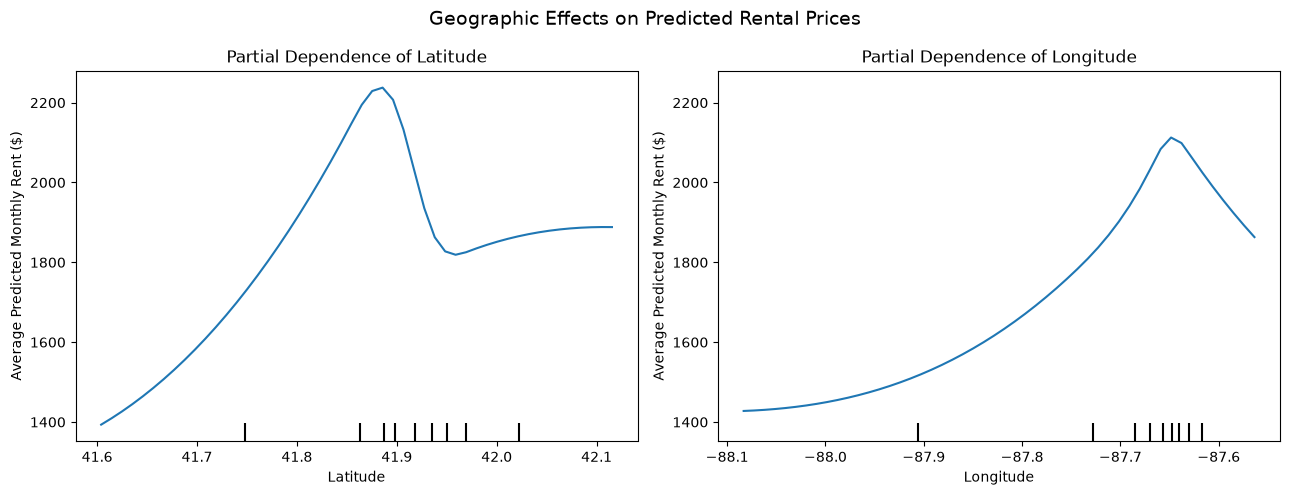

In [12]:
# Use a reproducible sample of training observations
X_plot = X_train.sample(
    n=2000,
    random_state=seed
)

# Create partial dependence plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

PartialDependenceDisplay.from_estimator(
    geo_ridge_model,
    X_plot,
    features=["latitude", "longitude"],
    grid_resolution=50,
    percentiles=(0.05, 0.95),
    ax=axes
)

# Customize plot titles and labels
axes[0].set_title("Partial Dependence of Latitude")
axes[0].set_xlabel("Latitude")
axes[0].set_ylabel("Average Predicted Monthly Rent ($)")

axes[1].set_title("Partial Dependence of Longitude")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Average Predicted Monthly Rent ($)")

plt.suptitle(
    "Geographic Effects on Predicted Rental Prices",
    fontsize=14
)

plt.tight_layout()
plt.show()


### 4.2 Interpretation of Partial Dependence Results

The partial dependence plots reveal nonlinear relationships between geographic coordinates and predicted monthly rents.

For latitude, predicted rents increase from approximately $1,390 at 41.60 to a local maximum of $2,240 near 41.89. They then decline sharply before stabilizing at approximately $1,880 at higher latitudes.

For longitude, predicted rents generally increase from west to east, reaching a local maximum of approximately $2,110 near -87.65, followed by a decline toward the eastern end of the plotted range.

These patterns demonstrate that the spline-based model captures nonlinear geographic variation in rental price predictions.

However, the plots represent model-based partial dependence rather than observed average rents at specific locations. They should not be interpreted as causal geographic effects. Additionally, varying one coordinate while holding the other predictors fixed may produce unrealistic geographic combinations.

Although the geographic effects exhibit nonlinear patterns, their incremental predictive contribution remains modest when ZIP code and property characteristics are already included in the model.

Because ZIP code remains fixed while geographic coordinates vary, the partial dependence plots may evaluate combinations that do not correspond to actual locations. The curves therefore describe the model's estimated response to coordinate changes rather than observed spatial rental price patterns.

## 5. Conclusions

This notebook explored the use of spline-based geospatial regression to predict monthly rental prices in the Chicago rental market.

The model combined structural property characteristics, temporal variables, ZIP code, and geographic coordinates. Nonlinear effects of latitude and longitude were represented using spline transformations, while Ridge regression provided regularization.

### 5.1 Main Findings

**Predictive performance**

The geospatial Ridge model achieved the following validation results:

- MAE: $329.50
- RMSE: $546.74
- $R^2$: 0.6822

The geospatial Ridge model achieved slightly better validation performance than the preliminary linear regression. However, this comparison should be interpreted cautiously because the models differ not only in their geographic predictors but also in their regularization and preprocessing procedures.

A more controlled comparison was conducted between two Ridge models with identical preprocessing and regularization settings, differing only in the inclusion of geographic coordinates. This comparison provides a more reliable assessment of the incremental predictive contribution of latitude and longitude.

Despite these improvements, Gradient Boosting remained the strongest predictive model, achieving a validation MAE of $229.22 and an $R^2$ of 0.8331.

**Contribution of geographic coordinates**

Adding latitude and longitude to an otherwise identical Ridge model reduced validation MAE from $331.28 to $329.50, an improvement of approximately 0.54%.

This modest improvement suggests that geographic coordinates provide limited additional predictive information when ZIP code and property characteristics are already included.

**Geographic interpretation**

Partial dependence plots revealed nonlinear relationships between latitude, longitude, and predicted rental prices.

These patterns illustrate the flexibility of spline transformations in capturing geographic variation. However, they represent model-based associations rather than causal effects or observed neighborhood-level rental differences.

### 5.2 Model Comparison

The following table summarizes the validation performance of the main regression models evaluated in this project.

| Model | MAE ($) | RMSE ($) | $R^2$ |
|---|---:|---:|---:|
| Gradient Boosting | 229.22 | 396.24 | 0.8331 |
| Geospatial Ridge | 329.50 | 546.74 | 0.6822 |
| Ridge Without Geographic Coordinates | 331.28 | 548.81 | 0.6798 |
| Preliminary Linear Regression | 334.62 | 551.74 | 0.6764 |

Gradient Boosting achieved the best predictive performance among these models.

The geospatial Ridge model performed slightly better than both the Ridge model without coordinates and the preliminary linear regression. However, the controlled comparison between the two Ridge models indicates that geographic coordinates contributed only a modest improvement in predictive accuracy.

These results highlight a trade-off between predictive performance and model interpretability. While Gradient Boosting provides more accurate predictions, the geospatial Ridge model offers a relatively simple framework for examining nonlinear geographic effects.

### 5.3 Limitations

The model uses separate additive functions for latitude and longitude and therefore does not explicitly capture interactions between geographic coordinates.

Furthermore, ZIP code and geographic coordinates contain overlapping spatial information, which may limit the incremental predictive contribution of the spline features.

### 5.4 Final Assessment

The geospatial Ridge model provides an interpretable approach to incorporating geographic information into rental price prediction.

However, the preliminary Gradient Boosting model remains the strongest predictive model evaluated so far.

Future work could explore spatial interactions or more flexible geographic representations if improved geographic modeling becomes a project priority.